# PAF Project Group 6 — Task 3: Predictive Modelling
## Golden Hour Fatality Triage

**Contributors:** Joao (Person 1): problem framing, metrics & baseline · Nuno (Person 4) & Pedro (Person 5): advanced models

**Business question.** When an emergency call arrives (t=0), should the dispatcher send a standard patrol / basic ambulance, or an immediate Advanced Life Support (ALS) unit or helicopter?

**Prediction.** Probability that the crash is fatal (`is_fatal = 1` when `accident_classification == 2`), using only information known at call intake.

This notebook reproduces the problem framing, metrics and baseline benchmark defined by Joao (see `contributions/person1_joao_problem_framing/`). Nuno and Pedro add their models in Section 7 and are evaluated with the same functions.

| Section | Content |
|---|---|
| 1 | Setup & data loading |
| 2 | Cleaning (from the Task 2 audit) |
| 3 | Target & base rates |
| 4 | Out-of-time split |
| 5 | Metrics: why not accuracy, Top-15% rule, economic threshold p* |
| 6 | Baseline benchmark: Dummy vs. Balanced Logistic Regression |
| 7 | Advanced models (Nuno & Pedro) |

## 1. Setup & data loading

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.calibration import CalibratedClassifierCV
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.frozen import FrozenEstimator
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (average_precision_score, brier_score_loss,
                             precision_recall_curve, roc_auc_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore")
RANDOM_STATE = 42

In [2]:
# Works locally (repo layout) and in Colab (manual upload)
DATA = Path("../data/raw/highway_accidents.csv")
if not DATA.exists():
    from google.colab import files
    files.upload()
    DATA = Path("highway_accidents.csv")

df = pd.read_csv(DATA, parse_dates=["date"])
print(f"Dataset Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")

Dataset Shape: 150,000 rows x 23 columns


## 2. Cleaning

Decisions taken from the Task 2 data-quality audit:
- **Drop corrupted row 57163** (more than 10 missing features).
- **Impute the 90 missing `road_direction` values** with the mode.
- **Exclude `latitude` / `longitude`**: 100% missing 2007–2016 (2017 GPS cliff), so they cannot be used as raw features.
- **Exclude `date` / `year`** as predictors: after the 2015 e-DAT reporting change, year captures *how crashes were logged*, not road risk.

In [3]:
nulls_per_row = df.isnull().sum(axis=1)
corrupted = df.index[nulls_per_row > 10].tolist()
print("Corrupted rows dropped:", corrupted)
df = df.drop(index=corrupted)

print("Missing road_direction before imputation:", df["road_direction"].isnull().sum())
df["road_direction"] = df["road_direction"].fillna(df["road_direction"].mode()[0])

df["year"] = df["date"].dt.year
df["is_fatal"] = (df["accident_classification"] == 2).astype(int)

Corrupted rows dropped: [57163]
Missing road_direction before imputation: 90


## 3. Target & base rates

Fatal crashes overall (2007-2025): 7,222 (4.81%)
Non-fatal overall:                 95.19%


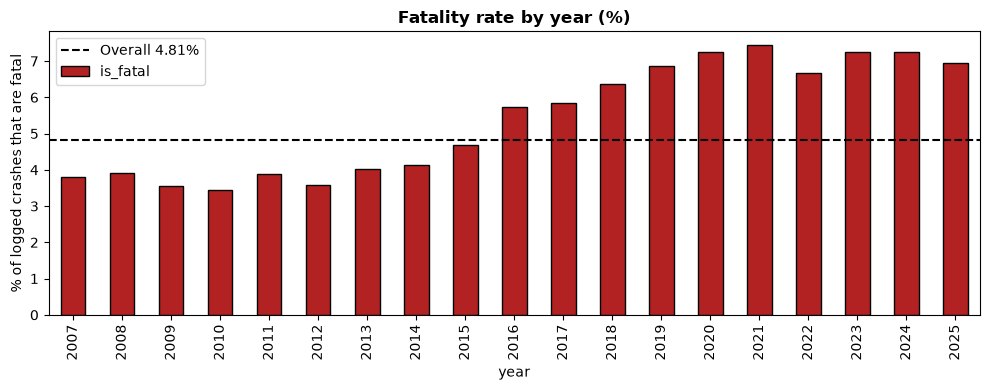

In [4]:
overall_rate = df["is_fatal"].mean()
print(f"Fatal crashes overall (2007-2025): {df['is_fatal'].sum():,} ({overall_rate:.2%})")
print(f"Non-fatal overall:                 {1 - overall_rate:.2%}")

rate_by_year = df.groupby("year")["is_fatal"].mean() * 100
ax = rate_by_year.plot(kind="bar", color="firebrick", edgecolor="black", figsize=(10, 4))
ax.axhline(overall_rate * 100, ls="--", color="black", label=f"Overall {overall_rate:.2%}")
ax.set_title("Fatality rate by year (%)", fontweight="bold")
ax.set_ylabel("% of logged crashes that are fatal")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Out-of-time split

No random shuffling: the model is trained on the past and evaluated on the most recent years, as it would be used in production.

| Set | Years |
|---|---|
| Train | 2007–2021 |
| Validation | 2022–2023 |
| Test | 2024–2025 |

In [5]:
train = df[df["year"] <= 2021]
val = df[df["year"].between(2022, 2023)]
test = df[df["year"] >= 2024]

split_summary = pd.DataFrame({
    "Rows": [len(train), len(val), len(test)],
    "Fatal rate (%)": [s["is_fatal"].mean() * 100 for s in (train, val, test)],
}, index=["Train 2007-2021", "Validation 2022-2023", "Test 2024-2025"]).round(2)
split_summary

,Rows,Fatal rate (%)
Train 2007-2021,130870,4.49
Validation 2022-2023,9073,6.97
Test 2024-2025,10056,7.11


In [6]:
CATEGORICAL = ["roadway_type", "area_type", "time_of_day", "highway_type", "road_direction"]
NUMERIC = ["km", "Uphill", "Crossing", "Curve", "Downhill", "Temporary_Detour", "Roadworks",
           "Road_Intersection", "Bridge", "Straight", "Regulated_Uturn", "Roundabout",
           "Tunnel", "Overpass"]
FEATURES = CATEGORICAL + NUMERIC

X_train, y_train = train[FEATURES], train["is_fatal"]
X_val, y_val = val[FEATURES], val["is_fatal"]
X_test, y_test = test[FEATURES], test["is_fatal"]
print(f"{len(FEATURES)} features, all known at t=0 (road geometry, location marker, time of day)")

19 features, all known at t=0 (road geometry, location marker, time of day)


## 5. Metrics

### Why not accuracy
A model that always predicts "no fatality" looks excellent on accuracy but catches no deaths.

In [7]:
accuracy_always_no = 1 - y_test.mean()
print(f"'No fatality, ever' on the 2024-2025 test set: accuracy {accuracy_always_no:.2%}, recall 0.00%")

'No fatality, ever' on the 2024-2025 test set: accuracy 92.89%, recall 0.00%


### Metrics used
- **PR-AUC**: ranking quality on a rare event (a random model scores the base rate).
- **Recall / Precision / Lift @ Top 15%**: ALS capacity covers 15% of calls. Of all fatal crashes, how many fall in the 15% highest-risk calls, and how much better than random?
- **Brier score**: are the predicted probabilities trustworthy (calibration)? Lower is better.
- ROC-AUC reported for reference.

In [8]:
CAPACITY = 0.15  # share of calls that ALS can serve


def top_k_metrics(y_true, y_prob, k=CAPACITY):
    """Recall, precision and lift when dispatching ALS to the top-k share of highest-risk calls."""
    y_true = np.asarray(y_true)
    if np.ptp(y_prob) == 0:  # constant scores cannot rank: top-k is a random pick
        return k, y_true.mean(), 1.0
    n_top = int(np.ceil(len(y_true) * k))
    top_idx = np.argsort(-y_prob, kind="stable")[:n_top]
    recall = y_true[top_idx].sum() / y_true.sum()
    precision = y_true[top_idx].mean()
    return recall, precision, recall / k


def evaluate(name, y_true, y_prob):
    recall, precision, lift = top_k_metrics(y_true, y_prob)
    return pd.Series({
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "PR-AUC": average_precision_score(y_true, y_prob),
        "Recall@15%": recall,
        "Precision@15%": precision,
        "Lift@15%": lift,
        "Brier": brier_score_loss(y_true, y_prob),
    }, name=name)

### Economic threshold p*
Dispatching ALS costs about €2,500; a prevented death is valued at about €50,000. Dispatch is worth it when expected benefit exceeds cost:

$$p \cdot B > C \;\Rightarrow\; p^* = \frac{C}{B}$$

In [9]:
COST_ALS = 2_500
BENEFIT_PREVENTED_DEATH = 50_000
p_star = COST_ALS / BENEFIT_PREVENTED_DEATH
print(f"p* = {COST_ALS:,} / {BENEFIT_PREVENTED_DEATH:,} = {p_star:.1%}")
print(f"Test-set base rate = {y_test.mean():.2%} > p*, so capacity (Top 15%) is the binding constraint.")

p* = 2,500 / 50,000 = 5.0%
Test-set base rate = 7.11% > p*, so capacity (Top 15%) is the binding constraint.


## 6. Baseline benchmark

1. **Dummy classifier**: always predicts the majority class ("no fatality"), so every crash gets probability 0.
2. **Balanced Logistic Regression**: one-hot encoded categoricals + scaled numeric features, `class_weight="balanced"` to counter the 5% fatal rate. Preprocessing is fitted on Train only.

In [10]:
dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
p_dummy = dummy.predict_proba(X_test)[:, 1]

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])
logreg = Pipeline([
    ("prep", preprocess),
    ("model", LogisticRegression(class_weight="balanced", max_iter=2000, random_state=RANDOM_STATE)),
])
logreg.fit(X_train, y_train)
p_logreg = logreg.predict_proba(X_test)[:, 1]

results = pd.DataFrame([
    evaluate("Dummy (Baseline)", y_test, p_dummy),
    evaluate("Balanced Logistic Regression", y_test, p_logreg),
])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552


### Comparison with Joao's reported numbers

The Dummy row reproduces exactly. The logistic regression lands slightly above Joao's figures: their exact feature set and preprocessing were not shared, so small differences are expected. **The numbers in this notebook are the reproducible ones to use on the slides.**

In [11]:
joao = pd.DataFrame({
    "ROC-AUC": [0.5000, 0.6643], "PR-AUC": [0.0711, 0.1158],
    "Recall@15%": [0.1500, 0.2895], "Precision@15%": [0.0711, 0.1372],
    "Lift@15%": [1.00, 1.93], "Brier": [0.0711, 0.2499],
}, index=results.index)

comparison = pd.concat({"Joao (reported)": joao, "This notebook": results}, axis=1)
comparison.T.round(4)

Dummy (Baseline)  Balanced Logistic Regression
Joao (reported) ROC-AUC                  0.5000                        0.6643
                PR-AUC                   0.0711                        0.1158
                Recall@15%               0.1500                        0.2895
                Precision@15%            0.0711                        0.1372
                Lift@15%                 1.0000                        1.9300
                Brier                    0.0711                        0.2499
This notebook   ROC-AUC                  0.5000                        0.6659
                PR-AUC                   0.0711                        0.1221
                Recall@15%               0.1500                        0.3119
                Precision@15%            0.0711                        0.1478
                Lift@15%                 1.0000                        2.0793
                Brier                    0.0711                        0.2552

### Calibration (open flag from Joao)

Class balancing inflates probabilities: the Brier score is much worse than the dummy's. Before applying p* = 5%, the probabilities are re-calibrated on the **validation** set (isotonic regression, model frozen). Ranking metrics barely change; Brier should drop sharply.

In [12]:
logreg_cal = CalibratedClassifierCV(FrozenEstimator(logreg), method="isotonic")
logreg_cal.fit(X_val, y_val)
p_logreg_cal = logreg_cal.predict_proba(X_test)[:, 1]

results = pd.concat([results, evaluate("Balanced LR + isotonic calibration", y_test, p_logreg_cal).to_frame().T])
results.round(4)

,ROC-AUC,PR-AUC,Recall@15%,Precision@15%,Lift@15%,Brier
Dummy (Baseline),0.5000,0.0711,0.1500,0.0711,1.0000,0.0711
Balanced Logistic Regression,0.6659,0.1221,0.3119,0.1478,2.0793,0.2552
Balanced LR + isotonic calibration,0.6679,0.1180,0.3105,0.1471,2.0699,0.0645


In [13]:
dispatched = p_logreg_cal >= p_star
print(f"Calls above p* = {p_star:.0%}: {dispatched.mean():.1%} of test calls "
      f"(capacity is {CAPACITY:.0%})")
print(f"Fatal crashes among them: {y_test[dispatched].sum()} of {y_test.sum()} "
      f"({y_test[dispatched].sum() / y_test.sum():.1%})")

Calls above p* = 5%: 62.9% of test calls (capacity is 15%)
Fatal crashes among them: 592 of 715 (82.8%)


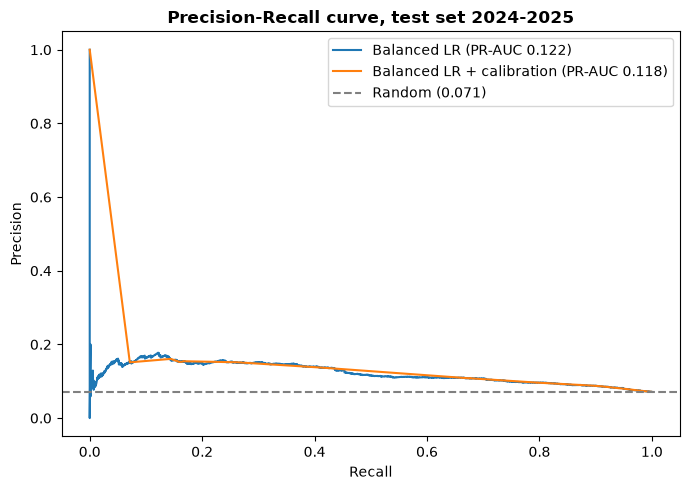

In [14]:
fig, ax = plt.subplots(figsize=(7, 5))
for name, p in [("Balanced LR", p_logreg), ("Balanced LR + calibration", p_logreg_cal)]:
    precision, recall, _ = precision_recall_curve(y_test, p)
    ax.plot(recall, precision, label=f"{name} (PR-AUC {average_precision_score(y_test, p):.3f})")
ax.axhline(y_test.mean(), ls="--", color="grey", label=f"Random ({y_test.mean():.3f})")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision-Recall curve, test set 2024-2025", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

## 7. Advanced models (Nuno & Pedro)

Use the same `X_train / X_val / X_test`, tune on validation only, and add each model to the table with:

```python
results = pd.concat([results, evaluate("My model", y_test, p_my_model).to_frame().T])
```

### 7.1 Model 1 (Nuno)

In [15]:
# Nuno: model

### 7.2 Model 2 (Pedro)

In [16]:
# Pedro: model